# Proyecto Final — `skin-wound-tracker`
**Visión Computacional con Deep Learning**  
Especialización en Inteligencia Artificial — Universidad Autónoma de Occidente (UAO) · Semestre 2026-1  
**Profesor:** Nicolas Llanos Neuta  

---

### Alcance del sistema (Enfoque: Heridas Crónicas / Clínicas — Solo Imágenes RGB)
Este notebook desarrolla de manera reproducible el pipeline completo de visión computacional para:
1. **Clasificación etiológica multiclase (5 clases clínicas):** `diabetic_foot_ulcer`, `pressure_ulcer`, `venous_ulcer`, `surgical_wound` y `normal_skin`.
2. **Segmentación binaria de área de úlcera:** cuantificación objetiva de la extensión lesional (píxeles y porcentaje) para seguimiento longitudinal.

> **Flujo de bloques del sistema (ver `docs/PIPELINE.md`):**  
> `01 DATOS (imagen RGB)` → `02 PREPROCESO (224×224 + 256×256)` → `03A INFERENCIA CLS + Grad-CAM` → `03B INFERENCIA SEG (condicional)` → `04 POSPROCESO` → `05 INTERFAZ / USO`.


---
## 0. Configuración, Librerías y Hardware
Importación de librerías base, fijación de semillas para reproducibilidad y verificación de GPU (CUDA).


In [1]:
import csv
import json
import os
import random
import subprocess
import sys
from collections import Counter
from pathlib import Path
from typing import Callable, Dict, List, Optional, Tuple

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image, ImageOps
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from torchvision import models, transforms

# Semilla global reproducible
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Dispositivo de cómputo
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Rutas del repositorio
PROJECT_ROOT = Path.cwd()
UNIFIED_DIR = PROJECT_ROOT / "dataset_unified"
SEG_DIR = PROJECT_ROOT / "dataset_segmentation"
META_DIR = PROJECT_ROOT / "metadata"
FIG_DIR = PROJECT_ROOT / "figures"

# Clases canónicas del proyecto
CANONICAL_CLASSES = [
    "diabetic_foot_ulcer",
    "pressure_ulcer",
    "venous_ulcer",
    "surgical_wound",
    "normal_skin",
]
CLASS_TO_IDX = {c: i for i, c in enumerate(CANONICAL_CLASSES)}
IDX_TO_CLASS = {i: c for i, c in enumerate(CANONICAL_CLASSES)}

plt.style.use("seaborn-v0_8-whitegrid")

print(f"Python       : {sys.version.split()[0]}")
print(f"PyTorch      : {torch.__version__}")
print(f"Dispositivo  : {DEVICE}")
if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(0)
    print(f"GPU          : {props.name} ({props.total_memory / (1024**3):.2f} GB VRAM)")
print(f"Directorio   : {PROJECT_ROOT}")


Python       : 3.12.14
PyTorch      : 2.6.0+cu124
Dispositivo  : cuda
GPU          : NVIDIA GeForce RTX 3050 Laptop GPU (4.00 GB VRAM)
Directorio   : /home/sgira/projects/vision/skin-wound-tracker


---
## 1. Fase 1 · Recolección y Exploración de Datos (Solo Imágenes Clínicas)

Los conjuntos de datos utilizados provienen exclusivamente de **fotografía clínica real** (sin textos ni metadatos externos) de 5 fuentes académicas verificadas:
1. **AZH / UWM** (*WoundTypeClassifier* + *ROI*): 5 clases clínicas.
2. **Medetec Wound Database** (`medetec-dataset/`): úlceras por presión, venosas, pie diabético y quirúrgicas *(excluyendo carpetas web `google-images-*`)*.
3. **SurgWound (OSWUMC, *npj Digital Medicine* 2026):** imágenes clínicas de heridas quirúrgicas.
4. **FUSeg (MICCAI 2021 / UWM):** úlceras de pie diabético + máscaras de segmentación binaria.
5. **Mendeley Lower Limb & Feet Wound v3 (`hsj38fwnvr`):** pies sanos (`Nomal/`) + pares imagen/máscara de segmentación.

> Si los directorios locales de datos no existen todavía (p. ej. al clonar el repositorio en otra máquina), la siguiente celda permite reconstruirlos automáticamente ejecutando `scripts/download_and_integrate.py`.


In [2]:
# Verificación de datasets locales (si no existen, se pueden descargar con el script reproducible)
if not (UNIFIED_DIR.exists() and SEG_DIR.exists()):
    print("Datasets no encontrados localmente. Ejecutando scripts/download_and_integrate.py...")
    subprocess.run(
        [sys.executable, str(PROJECT_ROOT / "scripts" / "download_and_integrate.py"), "--max-per-class", "500"],
        check=True,
    )
else:
    print("[OK] Datasets locales verificados:")
    print(f"  - Clasificación : {UNIFIED_DIR.resolve()}")
    print(f"  - Segmentación  : {SEG_DIR.resolve()}")

# Cargar reporte de auditoría y manifiestos
with open(META_DIR / "deduplication_report.json", "r", encoding="utf-8") as f:
    dedup_report = json.load(f)

df_balanced = pd.read_csv(META_DIR / "manifest_balanced.csv")
df_seg = pd.read_csv(META_DIR / "manifest_segmentation.csv")

print("\n=== Auditoría de Integridad y Cero Data Leakage ===")
print(f"Imágenes escaneadas        : {dedup_report['total_scanned']}")
print(f"Pool único desduplicado    : {dedup_report['accepted_unique_pool']}")
print(f"Dataset clasificación      : {dedup_report['balanced_total']}")
print(f"Pares de segmentación      : {dedup_report['segmentation_pairs_count']}")
print(f"Solapamiento hashes splits : {dedup_report['split_hash_overlap']}")
print(f"Solapamiento grupos splits : {dedup_report['split_group_overlap']}")


[OK] Datasets locales verificados:
  - Clasificación : /mnt/c/Users/sgira/Desktop/Proyectos_Antigravity/ESPECIALIZACION/proyecto_final_vision/dataset_unified
  - Segmentación  : /mnt/c/Users/sgira/Desktop/Proyectos_Antigravity/ESPECIALIZACION/proyecto_final_vision/dataset_segmentation

=== Auditoría de Integridad y Cero Data Leakage ===
Imágenes escaneadas        : 7869
Pool único desduplicado    : 5695
Dataset clasificación      : 2192
Pares de segmentación      : 1586
Solapamiento hashes splits : {'train_val': 0, 'train_test': 0, 'val_test': 0}
Solapamiento grupos splits : {'train_val': 0, 'train_test': 0, 'val_test': 0}


In [3]:
# Resumen tabular por clase, partición y fuente académica
split_table = pd.crosstab(df_balanced["class"], df_balanced["split"]).reindex(CANONICAL_CLASSES)[["train", "val", "test"]]
split_table["total"] = split_table.sum(axis=1)
split_table.loc["TOTAL"] = split_table.sum()

source_table = pd.crosstab(df_balanced["class"], df_balanced["source"]).reindex(CANONICAL_CLASSES)
source_table["total"] = source_table.sum(axis=1)

print("=== Distribución Clasificación (train / val / test) ===")
display(split_table)

print("\n=== Composición por Fuente Académica ===")
display(source_table)

print("\n=== Distribución Segmentación (pares imagen + máscara) ===")
seg_table = pd.crosstab(df_seg["source"], df_seg["split"])
seg_table["total"] = seg_table.sum(axis=1)
seg_table.loc["TOTAL"] = seg_table.sum()
display(seg_table)


=== Distribución Clasificación (train / val / test) ===


split,train,val,test,total
class,,,,
diabetic_foot_ulcer,348,77,75,500
pressure_ulcer,216,46,46,308
venous_ulcer,266,58,60,384
surgical_wound,348,76,76,500
normal_skin,350,75,75,500
TOTAL,1528,332,332,2192



=== Composición por Fuente Académica ===


source,AZH_UWM,FUSeg_UWM,Medetec,Mendeley_hsj38fwnvr,SurgWound_OSWUMC,total
class,,,,,,
diabetic_foot_ulcer,185,233,82,0,0,500
pressure_ulcer,134,0,174,0,0,308
venous_ulcer,250,0,134,0,0,384
surgical_wound,164,0,64,0,272,500
normal_skin,99,0,0,401,0,500



=== Distribución Segmentación (pares imagen + máscara) ===


split,test,train,val,total
source,,,,
FUSeg_UWM,0,791,195,986
Mendeley_hsj38fwnvr,120,420,60,600
TOTAL,120,1211,255,1586


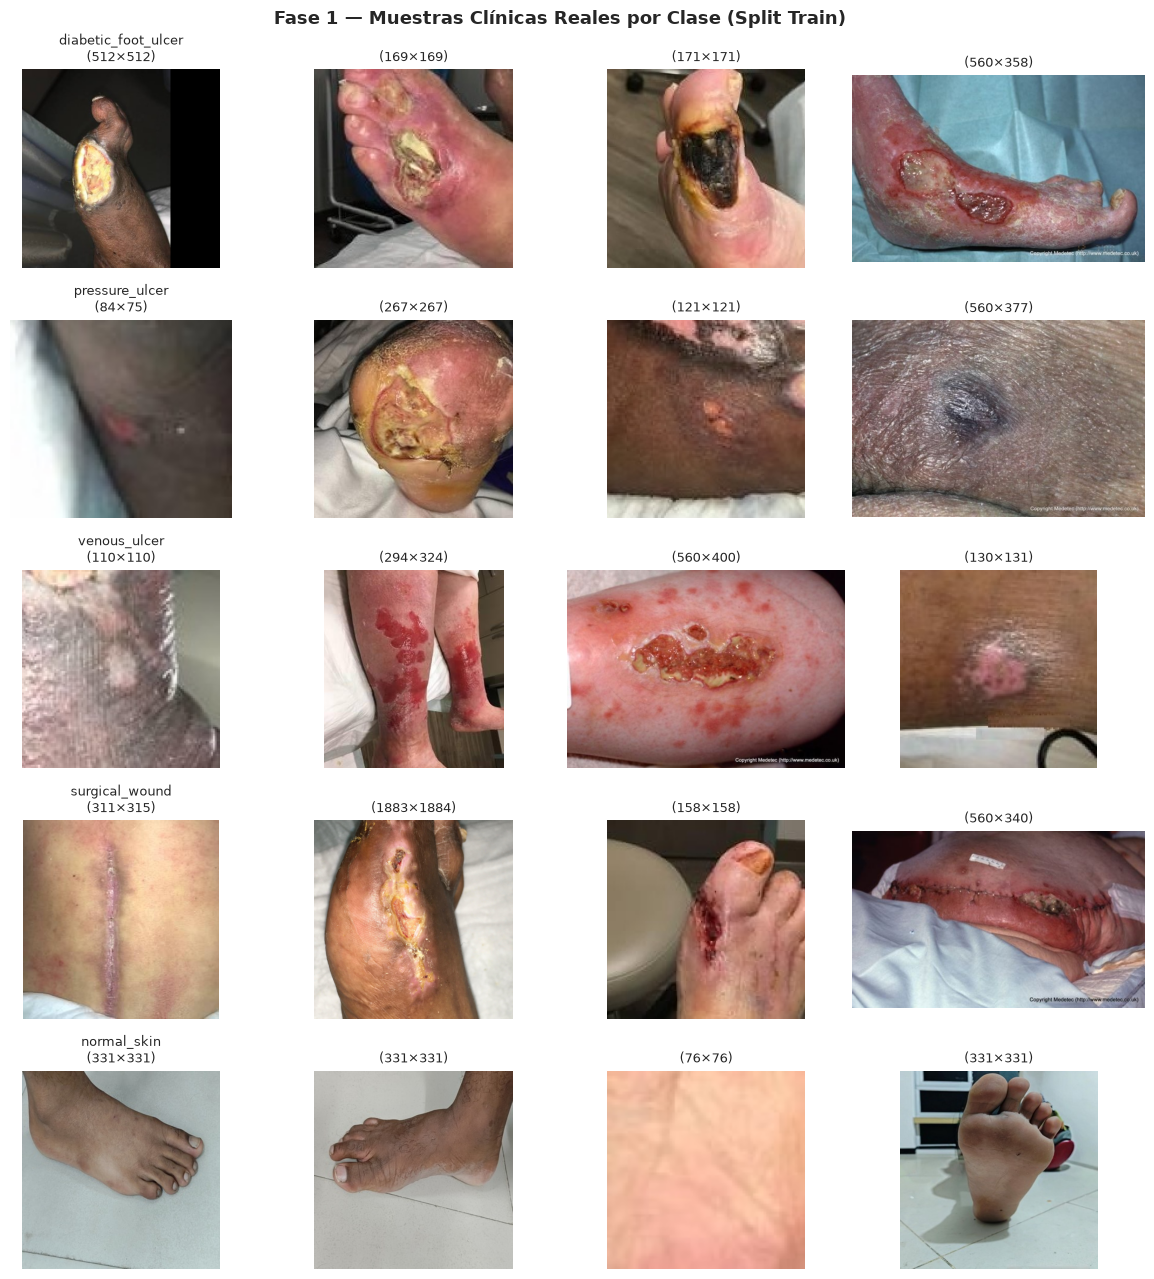

In [4]:
# Inspección visual: 3 muestras reales de cada una de las 5 clases (split train)
fig, axes = plt.subplots(len(CANONICAL_CLASSES), 4, figsize=(12, 13))
rng_vis = random.Random(SEED)

for row_idx, cls_name in enumerate(CANONICAL_CLASSES):
    cls_files = sorted((UNIFIED_DIR / "train" / cls_name).glob("*.*"))
    sampled = rng_vis.sample(cls_files, min(4, len(cls_files)))
    for col_idx, img_path in enumerate(sampled):
        with Image.open(img_path) as im:
            im_rgb = im.convert("RGB")
            w, h = im_rgb.size
            axes[row_idx, col_idx].imshow(im_rgb)
            axes[row_idx, col_idx].set_title(f"{cls_name}\n({w}×{h})" if col_idx == 0 else f"({w}×{h})", fontsize=9)
            axes[row_idx, col_idx].axis("off")

fig.suptitle("Fase 1 — Muestras Clínicas Reales por Clase (Split Train)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()


---
## 2. Fase 2 · Preprocesamiento de las Imágenes (`Bloque 02 · PREPROCESO`)

### 2.1 Estadísticos por canal (R, G, B) sobre `train`
Calculamos la media y desviación estándar real de nuestras imágenes de entrenamiento redimensionadas a `224×224` y las comparamos con los estadísticos estándar de **ImageNet** (`mean=(0.485, 0.456, 0.406)`, `std=(0.229, 0.224, 0.225)`).  
Dado que utilizaremos **Transfer Learning** con backbones preentrenados en ImageNet, normalizar con `IMAGENET_MEAN` e `IMAGENET_STD` mantiene alineada la distribución de entrada de los filtros convolucionales iniciales.


In [5]:
IMG_SIZE_CLS = 224
IMG_SIZE_SEG = 256
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}


def compute_channel_stats(split_dir: Path, img_size: int = 224) -> Tuple[Tuple[float, ...], Tuple[float, ...]]:
    """Calcula media y desviación estándar por canal RGB sobre todas las imágenes del split."""
    to_t = transforms.Compose([transforms.Resize((img_size, img_size)), transforms.ToTensor()])
    channel_sum = torch.zeros(3, dtype=torch.float64)
    channel_sq_sum = torch.zeros(3, dtype=torch.float64)
    total_pixels = 0

    for cls_name in CANONICAL_CLASSES:
        for img_p in sorted((split_dir / cls_name).iterdir()):
            if img_p.is_file() and img_p.suffix.lower() in IMAGE_EXTS:
                with Image.open(img_p) as im:
                    rgb = ImageOps.exif_transpose(im).convert("RGB")
                    t = to_t(rgb).to(torch.float64)  # (3, H, W)
                    channel_sum += t.sum(dim=(1, 2))
                    channel_sq_sum += (t ** 2).sum(dim=(1, 2))
                    total_pixels += t.shape[1] * t.shape[2]

    mean = channel_sum / total_pixels
    std = torch.sqrt((channel_sq_sum / total_pixels) - mean ** 2)
    return tuple(round(float(x), 4) for x in mean), tuple(round(float(x), 4) for x in std)


TRAIN_MEAN, TRAIN_STD = compute_channel_stats(UNIFIED_DIR / "train", img_size=IMG_SIZE_CLS)
print(f"Estadísticos reales (train 224×224) -> MEAN={TRAIN_MEAN} | STD={TRAIN_STD}")
print(f"Estadísticos ImageNet (Transfer L.) -> MEAN={IMAGENET_MEAN} | STD={IMAGENET_STD}")


Estadísticos reales (train 224×224) -> MEAN=(0.582, 0.4872, 0.4526) | STD=(0.2427, 0.2309, 0.2287)
Estadísticos ImageNet (Transfer L.) -> MEAN=(0.485, 0.456, 0.406) | STD=(0.229, 0.224, 0.225)


### 2.2 Transformaciones, `Dataset` y `DataLoaders` (Clasificación + Segmentación)

- **Aumentación en línea (*on-the-fly*) solo en `train`:** recorte escalado moderado (`scale=(0.75, 1.0)` para no perder la úlcera), giros horizontal/vertical, rotación `±20°` y variaciones leves de iluminación (`ColorJitter`).
- **Evaluación determinista (`val` / `test`):** solo `Resize` + `ToTensor` + `Normalize`.
- **Control de desbalance residual (`500` vs. `384` vs. `308`):** se calculan pesos inversos de clase (`class_weights`) exclusivamente sobre `train` para usarlos en la función de pérdida (`CrossEntropyLoss`) sin duplicar imágenes en disco.
- **Tamaño de lote (`BATCH_SIZE = 16`):** ajustado para entrenamiento estable en **RTX 3050 (4 GB VRAM)** con precisión mixta (`AMP`).


In [6]:
BATCH_SIZE_CLS = 16
BATCH_SIZE_SEG = 8
NUM_WORKERS = 2


def get_classification_transforms(img_size: int = IMG_SIZE_CLS, is_train: bool = True) -> transforms.Compose:
    if is_train:
        return transforms.Compose([
            transforms.RandomResizedCrop(img_size, scale=(0.75, 1.0)),
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.RandomVerticalFlip(p=0.3),
            transforms.RandomRotation(degrees=20),
            transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.10, hue=0.02),
            transforms.ToTensor(),
            transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
        ])
    return transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ])


class ChronicWoundDataset(Dataset):
    """Dataset de imágenes clínicas RGB para clasificación en 5 clases."""

    def __init__(self, root_dir: Path, split: str = "train", transform: Optional[Callable] = None, img_size: int = IMG_SIZE_CLS):
        self.split_dir = Path(root_dir) / split
        self.transform = transform or get_classification_transforms(img_size=img_size, is_train=(split == "train"))
        self.samples: List[Tuple[Path, int]] = []
        self.targets: List[int] = []

        for cls_name in CANONICAL_CLASSES:
            cls_dir = self.split_dir / cls_name
            cls_idx = CLASS_TO_IDX[cls_name]
            for img_p in sorted(cls_dir.iterdir()):
                if img_p.is_file() and img_p.suffix.lower() in IMAGE_EXTS:
                    self.samples.append((img_p, cls_idx))
                    self.targets.append(cls_idx)

    def __len__(self) -> int:
        return len(self.samples)

    def __getitem__(self, idx: int) -> Tuple[torch.Tensor, int]:
        img_p, target = self.samples[idx]
        with Image.open(img_p) as im:
            rgb = ImageOps.exif_transpose(im).convert("RGB")
            tensor = self.transform(rgb)
        return tensor, target

    def get_class_weights(self) -> torch.Tensor:
        counts = Counter(self.targets)
        total = len(self.targets)
        n_cls = len(CANONICAL_CLASSES)
        weights = [total / (n_cls * max(1, counts[i])) for i in range(n_cls)]
        return torch.tensor(weights, dtype=torch.float32)


class WoundSegmentationDataset(Dataset):
    """Dataset de pares (imagen clínica RGB, máscara binaria) para medición de área."""

    def __init__(self, project_root: Path, split: str = "train", img_size: int = IMG_SIZE_SEG, augment: bool = False):
        self.project_root = Path(project_root)
        self.img_size = img_size
        self.augment = augment
        self.pairs: List[Tuple[Path, Path]] = []

        manifest_csv = self.project_root / "metadata" / "manifest_segmentation.csv"
        with open(manifest_csv, "r", encoding="utf-8") as f:
            for row in csv.DictReader(f):
                if row["split"] == split:
                    img_p = self.project_root / row["image_rel_path"]
                    msk_p = self.project_root / row["mask_rel_path"]
                    if img_p.exists() and msk_p.exists():
                        self.pairs.append((img_p, msk_p))

        self.to_tensor = transforms.ToTensor()
        self.normalize = transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)

    def __len__(self) -> int:
        return len(self.pairs)

    def __getitem__(self, idx: int) -> Tuple[torch.Tensor, torch.Tensor]:
        img_p, msk_p = self.pairs[idx]
        with Image.open(img_p) as im, Image.open(msk_p) as mk:
            rgb = ImageOps.exif_transpose(im).convert("RGB").resize((self.img_size, self.img_size), Image.Resampling.BILINEAR)
            mask = mk.convert("L").resize((self.img_size, self.img_size), Image.Resampling.NEAREST)

            if self.augment:
                if torch.rand(1).item() > 0.5:
                    rgb = rgb.transpose(Image.Transpose.FLIP_LEFT_RIGHT)
                    mask = mask.transpose(Image.Transpose.FLIP_LEFT_RIGHT)
                if torch.rand(1).item() > 0.5:
                    rgb = rgb.transpose(Image.Transpose.FLIP_TOP_BOTTOM)
                    mask = mask.transpose(Image.Transpose.FLIP_TOP_BOTTOM)

            img_t = self.normalize(self.to_tensor(rgb))
            mask_arr = (np.asarray(mask, dtype=np.float32) > 127.0).astype(np.float32)
            mask_t = torch.from_numpy(mask_arr).unsqueeze(0)
        return img_t, mask_t


# Instanciar Datasets y DataLoaders
train_ds = ChronicWoundDataset(UNIFIED_DIR, split="train", img_size=IMG_SIZE_CLS)
val_ds   = ChronicWoundDataset(UNIFIED_DIR, split="val",   img_size=IMG_SIZE_CLS)
test_ds  = ChronicWoundDataset(UNIFIED_DIR, split="test",  img_size=IMG_SIZE_CLS)

CLASS_WEIGHTS = train_ds.get_class_weights()

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE_CLS, shuffle=True,  num_workers=NUM_WORKERS, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE_CLS, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE_CLS, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

seg_train_ds = WoundSegmentationDataset(PROJECT_ROOT, split="train", img_size=IMG_SIZE_SEG, augment=True)
seg_val_ds   = WoundSegmentationDataset(PROJECT_ROOT, split="val",   img_size=IMG_SIZE_SEG, augment=False)
seg_test_ds  = WoundSegmentationDataset(PROJECT_ROOT, split="test",  img_size=IMG_SIZE_SEG, augment=False)

seg_train_loader = DataLoader(seg_train_ds, batch_size=BATCH_SIZE_SEG, shuffle=True,  num_workers=NUM_WORKERS, pin_memory=True)
seg_val_loader   = DataLoader(seg_val_ds,   batch_size=BATCH_SIZE_SEG, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

print("=== DataLoaders Clasificación ===")
print(f"  train={len(train_ds)} ({len(train_loader)} batches) | val={len(val_ds)} | test={len(test_ds)}")
print(f"  CLASS_WEIGHTS (train): {[round(float(w), 4) for w in CLASS_WEIGHTS]}")

xb, yb = next(iter(train_loader))
print(f"  Lote clasificación -> x: {tuple(xb.shape)} {xb.dtype} [min={xb.min():.2f}, max={xb.max():.2f}] | y: {tuple(yb.shape)}")

print("\n=== DataLoaders Segmentación ===")
print(f"  seg_train={len(seg_train_ds)} | seg_val={len(seg_val_ds)} | seg_test={len(seg_test_ds)}")
sx, sm = next(iter(seg_train_loader))
print(f"  Lote segmentación  -> img: {tuple(sx.shape)} | mask: {tuple(sm.shape)} | valores máscara={sorted(torch.unique(sm).tolist())}")


=== DataLoaders Clasificación ===
  train=1528 (96 batches) | val=332 | test=332
  CLASS_WEIGHTS (train): [0.8782, 1.4148, 1.1489, 0.8782, 0.8731]


  Lote clasificación -> x: (16, 3, 224, 224) torch.float32 [min=-2.12, max=2.64] | y: (16,)

=== DataLoaders Segmentación ===
  seg_train=1211 | seg_val=255 | seg_test=120


  Lote segmentación  -> img: (8, 3, 256, 256) | mask: (8, 1, 256, 256) | valores máscara=[0.0, 1.0]


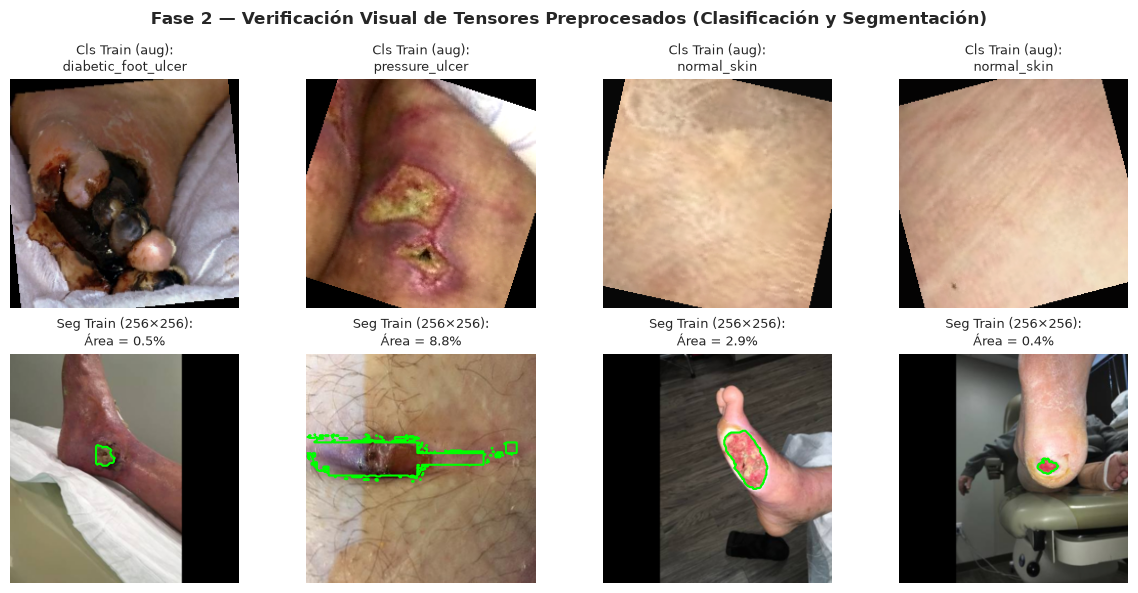

In [7]:
# Verificación visual del preprocesamiento: desnormalizar lote de train y pares de segmentación
def denormalize(tensor: torch.Tensor) -> np.ndarray:
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    img = (tensor.cpu() * std + mean).clamp(0, 1)
    return img.permute(1, 2, 0).numpy()


fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for i in range(4):
    axes[0, i].imshow(denormalize(xb[i]))
    axes[0, i].set_title(f"Cls Train (aug):\n{IDX_TO_CLASS[int(yb[i])]}", fontsize=9)
    axes[0, i].axis("off")

    img_vis = denormalize(sx[i])
    msk_vis = sm[i, 0].cpu().numpy()
    axes[1, i].imshow(img_vis)
    axes[1, i].contour(msk_vis, levels=[0.5], colors=["lime"], linewidths=1.5)
    area_pct = 100.0 * msk_vis.mean()
    axes[1, i].set_title(f"Seg Train (256×256):\nÁrea = {area_pct:.1f}%", fontsize=9)
    axes[1, i].axis("off")

fig.suptitle("Fase 2 — Verificación Visual de Tensores Preprocesados (Clasificación y Segmentación)", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()


---
## 3. Fase 3 · Selección y Arquitectura de los Modelos (`Bloques 03A y 03B`)

### 3.1 Justificación técnica de las arquitecturas candidatas
Con **2,192 imágenes** de clasificación clínica, **1,586 pares** de segmentación y una GPU **RTX 3050 (4 GB VRAM)**, entrenar redes profundas desde cero llevaría a sobreajuste rápido. Por ello empleamos **Transfer Learning** (pesos preentrenados en ImageNet) y definimos arquitecturas comparables y livianas en memoria:

| Módulo del Pipeline | Arquitectura | Rol en la experimentación | Justificación técnica |
| :--- | :--- | :--- | :--- |
| **`03A · Clasificador`** | **`ResNet-50`** | Línea base (*baseline*) CNN clásica | Conexiones residuales estables; referencia estándar en literatura de heridas (AZH/Medetec). |
| **`03A · Clasificador`** | **`EfficientNet-B0`** | Alternativa ligera y eficiente | Escalamiento compuesto profundidad/ancho/resolución; muy bajo consumo de VRAM y menor riesgo de sobreajuste. |
| **`03A · Clasificador`** | **`ConvNeXt-Tiny`** | CNN moderna de alto rendimiento | Kernels `7×7`, `LayerNorm` y diseño inspirado en ViT; excelente captura de textura peri-lesional. |
| **`03B · Segmentador`** | **`UNetResNet34`** | Segmentación binaria de área | Encoder `ResNet-34` preentrenado + *skip connections* en 4 escalas para preservar bordes irregulares de úlceras. |


### 3.2 Definición de Clasificadores (`Bloque 03A`) y Utilidad `GradCAM`


In [8]:
def build_classifier(
    arch_name: str,
    num_classes: int = len(CANONICAL_CLASSES),
    dropout: float = 0.3,
    pretrained: bool = True,
    freeze_backbone: bool = False,
) -> nn.Module:
    """Construye un clasificador multiclase preentrenado con cabeza regularizada."""
    arch = arch_name.lower()

    if arch == "resnet50":
        weights = models.ResNet50_Weights.DEFAULT if pretrained else None
        model = models.resnet50(weights=weights)
        if freeze_backbone:
            for p in model.parameters():
                p.requires_grad = False
        in_features = model.fc.in_features
        model.fc = nn.Sequential(nn.Dropout(p=dropout), nn.Linear(in_features, num_classes))

    elif arch == "efficientnet_b0":
        weights = models.EfficientNet_B0_Weights.DEFAULT if pretrained else None
        model = models.efficientnet_b0(weights=weights)
        if freeze_backbone:
            for p in model.parameters():
                p.requires_grad = False
        in_features = model.classifier[1].in_features
        model.classifier = nn.Sequential(nn.Dropout(p=dropout), nn.Linear(in_features, num_classes))

    elif arch == "convnext_tiny":
        weights = models.ConvNeXt_Tiny_Weights.DEFAULT if pretrained else None
        model = models.convnext_tiny(weights=weights)
        if freeze_backbone:
            for p in model.parameters():
                p.requires_grad = False
        in_features = model.classifier[2].in_features
        model.classifier[2] = nn.Sequential(nn.Dropout(p=dropout), nn.Linear(in_features, num_classes))

    else:
        raise ValueError(f"Arquitectura no soportada: {arch_name}. Opciones: resnet50, efficientnet_b0, convnext_tiny")

    return model


def get_gradcam_target_layer(model: nn.Module, arch_name: str) -> nn.Module:
    """Retorna la última capa convolucional de referencia para explicabilidad Grad-CAM."""
    arch = arch_name.lower()
    if arch == "resnet50":
        return model.layer4[-1]
    if arch == "efficientnet_b0":
        return model.features[-1]
    if arch == "convnext_tiny":
        return model.features[-1][-1]
    raise ValueError(f"Capa Grad-CAM no configurada para: {arch_name}")


class GradCAM:
    """Extractor ligero de mapas de activación Grad-CAM para auditoría visual clínica."""

    def __init__(self, model: nn.Module, target_layer: nn.Module):
        self.model = model
        self.activations = None
        self.gradients = None
        self._handles = [
            target_layer.register_forward_hook(self._save_activation),
            target_layer.register_full_backward_hook(self._save_gradient),
        ]

    def _save_activation(self, _module, _inp, output):
        self.activations = output.detach()

    def _save_gradient(self, _module, _grad_in, grad_out):
        self.gradients = grad_out[0].detach()

    def generate(self, x: torch.Tensor, class_idx: Optional[int] = None) -> np.ndarray:
        self.model.zero_grad(set_to_none=True)
        logits = self.model(x)
        if class_idx is None:
            class_idx = int(logits.argmax(dim=1).item())
        score = logits[:, class_idx].sum()
        score.backward()

        weights = self.gradients.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((weights * self.activations).sum(dim=1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[2:], mode="bilinear", align_corners=False)
        cam_np = cam[0, 0].cpu().numpy()
        cam_np = (cam_np - cam_np.min()) / (cam_np.max() - cam_np.min() + 1e-8)
        return cam_np

    def close(self):
        for h in self._handles:
            h.remove()

print("[OK] Constructores de clasificadores (ResNet-50, EfficientNet-B0, ConvNeXt-Tiny) y GradCAM definidos.")


[OK] Constructores de clasificadores (ResNet-50, EfficientNet-B0, ConvNeXt-Tiny) y GradCAM definidos.


### 3.3 Definición del Segmentador Binario (`Bloque 03B`: `UNetResNet34`) y Pérdida `BCEDiceLoss`


In [9]:
class ConvBlock(nn.Module):
    """Bloque convolucional doble Conv2d -> BatchNorm -> ReLU del decoder U-Net."""

    def __init__(self, in_ch: int, out_ch: int):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.block(x)


class UNetResNet34(nn.Module):
    """U-Net con encoder ResNet-34 preentrenado y conexiones residuales multiescala."""

    def __init__(self, pretrained: bool = True, out_channels: int = 1):
        super().__init__()
        weights = models.ResNet34_Weights.DEFAULT if pretrained else None
        enc = models.resnet34(weights=weights)

        # Encoder multiescala (canales: 64, 64, 128, 256, 512)
        self.stem = nn.Sequential(enc.conv1, enc.bn1, enc.relu)  # H/2,  64
        self.pool = enc.maxpool                                  # H/4
        self.enc1 = enc.layer1                                   # H/4,  64
        self.enc2 = enc.layer2                                   # H/8,  128
        self.enc3 = enc.layer3                                   # H/16, 256
        self.enc4 = enc.layer4                                   # H/32, 512

        # Decoder con skip connections
        self.dec4 = ConvBlock(512 + 256, 256)
        self.dec3 = ConvBlock(256 + 128, 128)
        self.dec2 = ConvBlock(128 + 64, 64)
        self.dec1 = ConvBlock(64 + 64, 32)
        self.final_conv = nn.Sequential(
            nn.Conv2d(32, 16, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True),
            nn.Conv2d(16, out_channels, kernel_size=1),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        s0 = self.stem(x)              # (B, 64, H/2, W/2)
        s1 = self.enc1(self.pool(s0))  # (B, 64, H/4, W/4)
        s2 = self.enc2(s1)             # (B, 128, H/8, W/8)
        s3 = self.enc3(s2)             # (B, 256, H/16, W/16)
        s4 = self.enc4(s3)             # (B, 512, H/32, W/32)

        d4 = self.dec4(torch.cat([F.interpolate(s4, size=s3.shape[2:], mode="bilinear", align_corners=False), s3], dim=1))
        d3 = self.dec3(torch.cat([F.interpolate(d4, size=s2.shape[2:], mode="bilinear", align_corners=False), s2], dim=1))
        d2 = self.dec2(torch.cat([F.interpolate(d3, size=s1.shape[2:], mode="bilinear", align_corners=False), s1], dim=1))
        d1 = self.dec1(torch.cat([F.interpolate(d2, size=s0.shape[2:], mode="bilinear", align_corners=False), s0], dim=1))
        out = F.interpolate(d1, size=x.shape[2:], mode="bilinear", align_corners=False)
        return self.final_conv(out)


class BCEDiceLoss(nn.Module):
    """Pérdida combinada BCEWithLogits + Soft Dice Loss para máscaras binarias desbalanceadas."""

    def __init__(self, bce_weight: float = 0.5, smooth: float = 1.0):
        super().__init__()
        self.bce_weight = bce_weight
        self.smooth = smooth
        self.bce = nn.BCEWithLogitsLoss()

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        bce_loss = self.bce(logits, targets)
        probs = torch.sigmoid(logits)
        dims = (1, 2, 3)
        intersection = (probs * targets).sum(dim=dims)
        dice_loss = 1.0 - ((2.0 * intersection + self.smooth) / (probs.sum(dim=dims) + targets.sum(dim=dims) + self.smooth)).mean()
        return self.bce_weight * bce_loss + (1.0 - self.bce_weight) * dice_loss


@torch.no_grad()
def compute_seg_metrics(logits: torch.Tensor, targets: torch.Tensor, threshold: float = 0.5, eps: float = 1e-6) -> Tuple[float, float]:
    """Calcula Dice Score e IoU (Jaccard) promedio en el lote."""
    preds = (torch.sigmoid(logits) > threshold).float()
    dims = (1, 2, 3)
    inter = (preds * targets).sum(dim=dims)
    union = preds.sum(dim=dims) + targets.sum(dim=dims) - inter
    dice = ((2.0 * inter + eps) / (preds.sum(dim=dims) + targets.sum(dim=dims) + eps)).mean().item()
    iou = ((inter + eps) / (union + eps)).mean().item()
    return dice, iou

print("[OK] Arquitectura UNetResNet34, pérdida BCEDiceLoss y métricas Dice/IoU definidas.")


[OK] Arquitectura UNetResNet34, pérdida BCEDiceLoss y métricas Dice/IoU definidas.


### 3.4 Verificación de *Forward Pass* y Consumo de VRAM en GPU
Comprobamos que las **4 arquitecturas** (3 clasificadores candidatos + 1 segmentador) reciben correctamente los tensores de nuestros `DataLoaders`, generan las dimensiones de salida exactas y corren sin desbordamiento de memoria en la GPU.


In [10]:
summary_rows = []

# 1. Prueba de los 3 clasificadores sobre un lote real de entrenamiento
x_cls_gpu = xb.to(DEVICE)
for arch in ["resnet50", "efficientnet_b0", "convnext_tiny"]:
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()
    model = build_classifier(arch, num_classes=len(CANONICAL_CLASSES), pretrained=True).to(DEVICE)
    model.eval()
    with torch.no_grad():
        out = model(x_cls_gpu)
    total_params = sum(p.numel() for p in model.parameters())
    train_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    peak_mb = torch.cuda.max_memory_allocated() / (1024 ** 2) if torch.cuda.is_available() else 0.0
    summary_rows.append({
        "Modelo": arch,
        "Tarea": "Clasificación (03A)",
        "Entrada": str(tuple(x_cls_gpu.shape)),
        "Salida": str(tuple(out.shape)),
        "Parámetros (M)": round(total_params / 1e6, 2),
        "Entrenables (M)": round(train_params / 1e6, 2),
        "VRAM pico (MB)": round(peak_mb, 1),
    })
    del model, out
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# 2. Prueba del segmentador UNetResNet34 sobre un lote real de segmentación
x_seg_gpu = sx.to(DEVICE)
m_seg_gpu = sm.to(DEVICE)
if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()
seg_model = UNetResNet34(pretrained=True).to(DEVICE)
seg_model.eval()
with torch.no_grad():
    seg_out = seg_model(x_seg_gpu)
    init_loss = BCEDiceLoss()(seg_out, m_seg_gpu).item()
    init_dice, init_iou = compute_seg_metrics(seg_out, m_seg_gpu)

total_params = sum(p.numel() for p in seg_model.parameters())
train_params = sum(p.numel() for p in seg_model.parameters() if p.requires_grad)
peak_mb = torch.cuda.max_memory_allocated() / (1024 ** 2) if torch.cuda.is_available() else 0.0
summary_rows.append({
    "Modelo": "UNetResNet34",
    "Tarea": "Segmentación (03B)",
    "Entrada": str(tuple(x_seg_gpu.shape)),
    "Salida": str(tuple(seg_out.shape)),
    "Parámetros (M)": round(total_params / 1e6, 2),
    "Entrenables (M)": round(train_params / 1e6, 2),
    "VRAM pico (MB)": round(peak_mb, 1),
})
del seg_model, seg_out
if torch.cuda.is_available():
    torch.cuda.empty_cache()

df_arch = pd.DataFrame(summary_rows)
display(df_arch)
print(f"\n[OK] Forward pass verificado en {DEVICE}. Loss inicial segmentación (sin entrenar): {init_loss:.4f} (Dice={init_dice:.4f}, IoU={init_iou:.4f})")


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /home/sgira/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


0.1%

0.3%

0.4%

0.5%

0.6%

... (2,482 outputs left out)

100.0%

100.0%

,Modelo,Tarea,Entrada,Salida,Parámetros (M),Entrenables (M),VRAM pico (MB)
0,resnet50,Clasificación (03A),"(16, 3, 224, 224)","(16, 5)",23.52,23.52,261.7
1,efficientnet_b0,Clasificación (03A),"(16, 3, 224, 224)","(16, 5)",4.01,4.01,193.1
2,convnext_tiny,Clasificación (03A),"(16, 3, 224, 224)","(16, 5)",27.82,27.82,308.8
3,UNetResNet34,Segmentación (03B),"(8, 3, 256, 256)","(8, 1, 256, 256)",24.43,24.43,324.5



[OK] Forward pass verificado en cuda. Loss inicial segmentación (sin entrenar): 0.8477 (Dice=0.0495, IoU=0.0262)


---
## 4. Siguiente Etapa (Fases 4, 5 y 6 — Pendiente)
En el siguiente bloque del desarrollo implementaremos directamente en este notebook:
1. **Fase 4 · Entrenamiento y Experimentación:** entrenamiento en GPU (`AMP`, `AdamW`, `CosineAnnealingLR`, `EarlyStopping`) comparando los 3 clasificadores (`ResNet-50`, `EfficientNet-B0`, `ConvNeXt-Tiny`) y `UNetResNet34`, guardando curvas y checkpoints.
2. **Fase 5 · Evaluación en `test`:** matriz de confusión, `Macro-F1`, `Recall` por clase, `Dice`/`IoU` y análisis de aciertos/errores con **Grad-CAM**.
3. **Fase 6 · Pipeline Funcional (`01 → 05`):** integración del clasificador + segmentador condicional + cálculo de área y demostración de seguimiento longitudinal.
